# 1. How big should an arbitrage trade be?

The original notebook asks for an arbitrage on a *fixed* 10 DAI. This notebook asks the better question: for two pools quoting the same pair at different prices, what trade size maximises profit, and can it be written in closed form?

**Derivation.** One constant-product hop with fee `f` (`g = 1 - f`) maps input `a` to `g R_out a / (R_in + g a)`: a Moebius map `a -> alpha a / (beta + delta a)`. Compositions of such maps keep the form `A a / (B + C a)`, with `A' = alpha A`, `B' = beta B`, `C' = beta C + delta A` per extra hop. Profit `A a/(B + C a) - a` is concave in `a`; setting its derivative to zero gives

`a* = (sqrt(AB) - B) / C`, `profit* = (sqrt(A) - sqrt(B))^2 / C`, profitable iff `A > B`.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, matplotlib.pyplot as plt, matplotlib as mpl
from amm import *
INK, INDIGO, AMBER, GREEN, CORAL, GREY = "#0E1A2B", "#4B3FE4", "#E8982B", "#0E9F7E", "#E5484D", "#8A94A6"
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "font.size": 10, "axes.grid": True, "grid.color": "#E3E7EE", "grid.linewidth": .7, "axes.axisbelow": True})

## The notebook's pools, two ways

In [2]:
from amm.legacy import NotebookPool, calculate_arbitrage
# Original notebook convention (fee surcharge on top of input), 10 DAI requested
nb_res = calculate_arbitrage(NotebookPool("A", 400, 1200), NotebookPool("B", 2000, 5800), 10)
print("Original notebook, 10 DAI requested: ETH required %.6f, profit %.6f ETH" % nb_res[:2])

# Uniswap v2 math (fee on input, both legs), closed-form optimum
A_, B_ = Pool("DAI", "ETH", 400, 1200), Pool("DAI", "ETH", 2000, 5800)
r = two_pool_arbitrage(A_, B_)
print(f"v2 closed form: start with {r.amount_in:.6f} {r.start_token}, buy {r.amount_mid:.6f} DAI in pool {'B' if r.buy_pool==1 else 'A'}, "
      f"get back {r.amount_out:.6f} {r.start_token}; profit {r.profit:.6f} {r.start_token}")
first, second = (A_, B_) if r.buy_pool == 0 else (B_, A_)
from amm.arbitrage import simulate_route
print(f"v2 profit if you trade the notebook's size ({nb_res[0]:.6f} ETH): {simulate_route(first, second, r.start_token, nb_res[0]):.6f} ETH")

Original notebook, 10 DAI requested: ETH required 29.233166, profit 0.035127 ETH
v2 closed form: start with 13.650814 ETH, buy 4.682069 DAI in pool B, get back 13.842526 ETH; profit 0.191712 ETH
v2 profit if you trade the notebook's size (29.233166 ETH): -0.050798 ETH


## Profit curve and the optimum

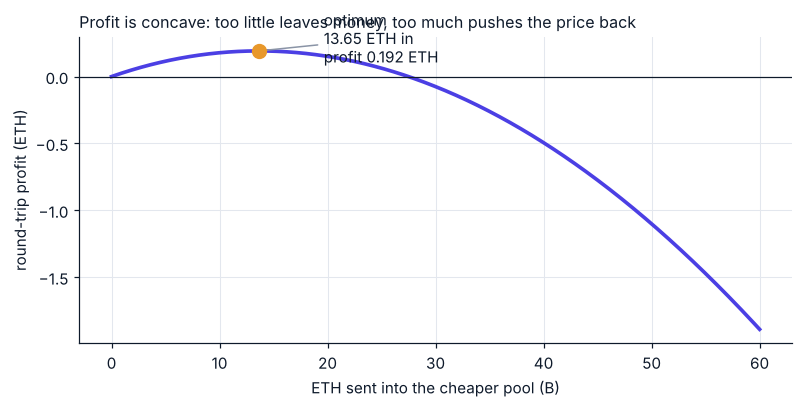

In [3]:
amounts = np.linspace(0, 60, 601)
prof = profit_curve(first, second, r.start_token, amounts)
fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.plot(amounts, prof, color=INDIGO, lw=2.4)
ax.axhline(0, color=INK, lw=.8)
ax.plot([r.amount_in], [r.profit], "o", color=AMBER, ms=9, zorder=5)
ax.annotate(f"optimum\n{r.amount_in:.2f} ETH in\nprofit {r.profit:.3f} ETH", (r.amount_in, r.profit), (r.amount_in + 6, r.profit * .55), color=INK,
            arrowprops=dict(arrowstyle="-", color=GREY))
ax.set_xlabel("ETH sent into the cheaper pool (B)"); ax.set_ylabel("round-trip profit (ETH)")
ax.set_title("Profit is concave: too little leaves money, too much pushes the price back", loc="left", fontsize=10.5, color=INK)
fig.tight_layout(); fig.savefig("../assets/profit_curve.png", dpi=150); plt.show()

## Verification against brute force

In [4]:
import random
rng = random.Random(2024)
rows, worst_p, worst_a = 0, 0.0, 0.0
for _ in range(300):
    a = Pool("X", "Y", rng.uniform(50, 5000), rng.uniform(50, 5000), fee=rng.choice([0.0005, 0.003, 0.01]))
    b = Pool("X", "Y", rng.uniform(50, 5000), rng.uniform(50, 5000), fee=rng.choice([0.0005, 0.003, 0.01]))
    res = two_pool_arbitrage(a, b)
    if res is None: continue
    f_, s_ = (a, b) if res.buy_pool == 0 else (b, a)
    a_bf, p_bf = brute_force_optimum(f_, s_, res.start_token, grid=2001)
    worst_p = max(worst_p, abs(res.profit / p_bf - 1)); worst_a = max(worst_a, abs(res.amount_in / a_bf - 1)); rows += 1
print(f"{rows} random profitable pool pairs checked")
print(f"max relative error of closed-form profit vs brute force: {worst_p:.2e}")
print(f"max relative error of closed-form size   vs brute force: {worst_a:.2e}")

297 random profitable pool pairs checked
max relative error of closed-form profit vs brute force: 1.52e-13
max relative error of closed-form size   vs brute force: 2.42e-07


## When is there anything to trade? The no-arbitrage band

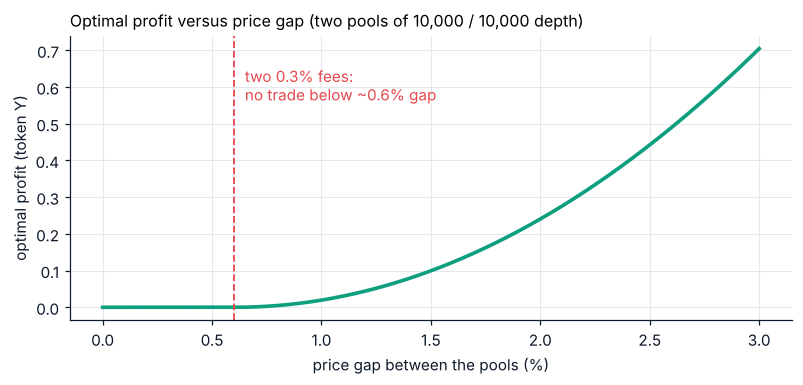

smallest gap with positive profit on this grid: 0.61%


In [5]:
gaps = np.linspace(0, 0.03, 301)
profits = []
for g_ in gaps:
    a = Pool("X", "Y", 10_000, 10_000); b = Pool("X", "Y", 10_000, 10_000 * (1 + g_))
    res = two_pool_arbitrage(a, b); profits.append(res.profit if res else 0.0)
fig, ax = plt.subplots(figsize=(7.4, 3.6))
ax.plot(gaps * 100, profits, color=GREEN, lw=2.4); ax.axvline(0.6, color=CORAL, ls="--", lw=1.2)
ax.text(0.65, max(profits) * .8, "two 0.3% fees:\nno trade below ~0.6% gap", color=CORAL)
ax.set_xlabel("price gap between the pools (%)"); ax.set_ylabel("optimal profit (token Y)")
ax.set_title("Optimal profit versus price gap (two pools of 10,000 / 10,000 depth)", loc="left", fontsize=10.5)
fig.tight_layout(); fig.savefig("../assets/no_arb_band.png", dpi=150); plt.show()
first_gap = gaps[next(i for i, p in enumerate(profits) if p > 0)]
print(f"smallest gap with positive profit on this grid: {first_gap*100:.2f}%")

## What does it pay in dollars? A mainnet-sized ETH/USDC example

**Assumptions (all editable, none fetched from a live market).**
- Two v2-style ETH/USDC pools, each 10,000 ETH and 20,000,000 USDC (TVL about $40M, price $2,000 per ETH), fee 0.3% each. The second pool's USDC reserve is scaled up to create a price gap.
- Gas: 150,000 gas units for the two-swap transaction x 20 gwei x $2,000 per ETH = **$6** per attempt (a parameter, shown for several values below).
- Optional flash-loan fee: a proportional fee on the borrowed input (0 or 0.05% here; real values depend on the lender).
- Net profit = swap output - input - flash fee - gas. Ignored: competition from other searchers (priority fees, MEV auctions), other trades hitting the pools in the same block, price movement during inclusion, Uniswap v3 liquidity ticks.

In [6]:
ETH_USD, GWEI, GAS_UNITS = 2000.0, 20.0, 150_000
gas_usd = GAS_UNITS * GWEI * 1e-9 * ETH_USD
def gas_map(usd): return {"USDC": usd, "ETH": usd / ETH_USD}
base = Pool("ETH", "USDC", 10_000, 20_000_000)
print(f"gas per attempt: ${gas_usd:.2f}")
print("gap    size (USDC)   gross $    gas $   flash $    net $   net/size")
for gap in (0.004, 0.006, 0.007, 0.008, 0.010, 0.020, 0.050):
    other = Pool("ETH", "USDC", 10_000, 20_000_000 * (1 + gap))
    r = two_pool_arbitrage(base, other, gas_map(gas_usd), flash_fee=0.0005)
    if r is None: print(f"{gap*100:>4.1f}%  not worth sending"); continue
    usd = 1.0 if r.start_token == "USDC" else ETH_USD
    print(f"{gap*100:>4.1f}%  {r.amount_in*usd:>11,.0f} {r.gross_profit*usd:>9,.2f} {r.gas_cost*usd:>8,.2f} {r.flash_cost*usd:>8,.2f} {r.profit*usd:>9,.2f}  {r.profit/r.amount_in*1e4:>6.2f} bp")

gas per attempt: $6.00
gap    size (USDC)   gross $    gas $   flash $    net $   net/size
 0.4%  not worth sending
 0.6%  not worth sending
 0.7%  not worth sending
 0.8%  not worth sending
 1.0%       17,300     38.46     6.00     8.65     23.81   13.76 bp
 2.0%       66,991    480.48     6.00    33.50    440.99   65.83 bp
 5.0%      214,622  4,695.14     6.00   107.31  4,581.83  213.48 bp


break-even price gap (smallest gap with net profit > 0), two 0.3% pools:
gas $     no flash loan    flash fee 0.05%
    0          0.603%          0.653%
    6          0.758%          0.809%
   30          0.951%          1.001%
  100          1.239%          1.289%


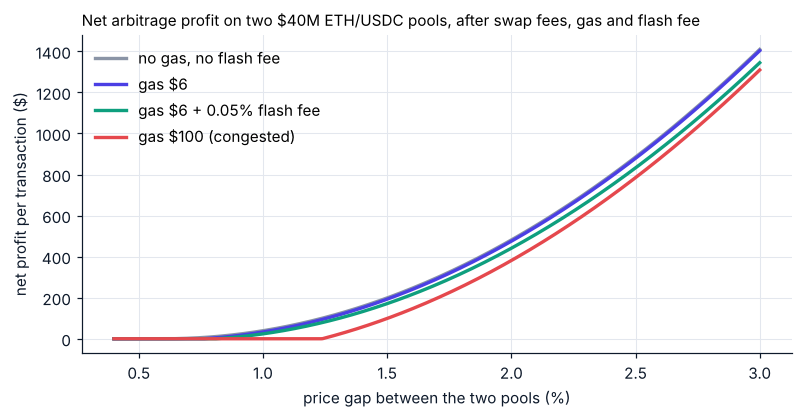

In [7]:
print("break-even price gap (smallest gap with net profit > 0), two 0.3% pools:")
print("gas $     no flash loan    flash fee 0.05%")
for g_usd in (0, 6, 30, 100):
    a_ = breakeven_mispricing(base, gas_map(g_usd)); b_ = breakeven_mispricing(base, gas_map(g_usd), flash_fee=0.0005)
    print(f"{g_usd:>5}   {a_*100:>12.3f}%   {b_*100:>12.3f}%")
gaps = np.linspace(0.004, 0.03, 400)
fig, ax = plt.subplots(figsize=(7.4, 3.9))
for usd, flash, col, lab in [(0, 0, GREY, "no gas, no flash fee"), (6, 0, INDIGO, "gas $6"), (6, 0.0005, GREEN, "gas $6 + 0.05% flash fee"), (100, 0, CORAL, "gas $100 (congested)")]:
    net = []
    for g_ in gaps:
        r = two_pool_arbitrage(base, Pool("ETH", "USDC", 10_000, 20e6 * (1 + g_)), gas_map(usd), flash)
        net.append(0 if r is None else r.profit * (1 if r.start_token == "USDC" else ETH_USD))
    ax.plot(gaps * 100, net, color=col, lw=2.2, label=lab)
ax.set_xlabel("price gap between the two pools (%)"); ax.set_ylabel("net profit per transaction ($)"); ax.legend(frameon=False)
ax.set_title("Net arbitrage profit on two $40M ETH/USDC pools, after swap fees, gas and flash fee", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig("../assets/net_profit_vs_gap.png", dpi=150); plt.show()